## DSCI552 Homework5

### 1.(a)

In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

cols = ['temp','nausea','lumbar_pain','urine_pushing',
        'micturition_pains','burning_urethra',
        'bladder_inflam','nephritis']  
df = pd.read_csv('../data/diagnosis.data', sep=r'\s+', header=None,
                 names=cols, encoding='utf-16')  
df['temp'] = df['temp'].astype(str).str.replace(',', '.').astype(float)
df[cols[1:]] = df[cols[1:]].eq('yes').astype(int)

In [3]:
print(df.shape)
df.head()

(120, 8)


,temp,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflam,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b)

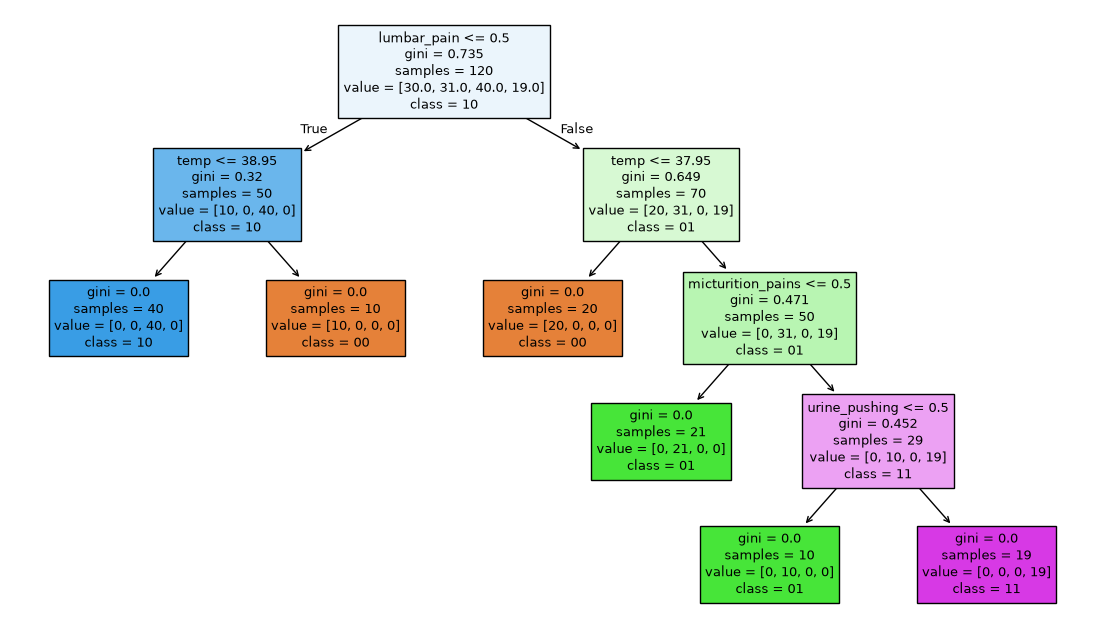

In [4]:
X = df[cols[:6]]
y = df['bladder_inflam'].astype(str) + df['nephritis'].astype(str)  # '00','01','10','11'

clf = DecisionTreeClassifier(random_state=0).fit(X, y)
plt.figure(figsize=(14, 8))
plot_tree(clf, feature_names=X.columns, class_names=clf.classes_, filled=True)
plt.show()

### (c)

In [5]:
def tree_to_rules(clf, feature_names):
    t, rules = clf.tree_, []
    def recurse(node, conds):
        if t.children_left[node] == -1:   # leaf
            cls = clf.classes_[np.argmax(t.value[node])]
            rules.append(f"IF {' AND '.join(conds)} THEN (bladder, nephritis) = {cls}")
            return
        f, th = feature_names[t.feature[node]], t.threshold[node]
        recurse(t.children_left[node],  conds + [f"{f} <= {th:.2f}"])
        recurse(t.children_right[node], conds + [f"{f} > {th:.2f}"])
    recurse(0, [])
    return rules

for r in tree_to_rules(clf, list(X.columns)): print(r)

IF lumbar_pain <= 0.50 AND temp <= 38.95 THEN (bladder, nephritis) = 10
IF lumbar_pain <= 0.50 AND temp > 38.95 THEN (bladder, nephritis) = 00
IF lumbar_pain > 0.50 AND temp <= 37.95 THEN (bladder, nephritis) = 00
IF lumbar_pain > 0.50 AND temp > 37.95 AND micturition_pains <= 0.50 THEN (bladder, nephritis) = 01
IF lumbar_pain > 0.50 AND temp > 37.95 AND micturition_pains > 0.50 AND urine_pushing <= 0.50 THEN (bladder, nephritis) = 01
IF lumbar_pain > 0.50 AND temp > 37.95 AND micturition_pains > 0.50 AND urine_pushing > 0.50 THEN (bladder, nephritis) = 11


### (d)

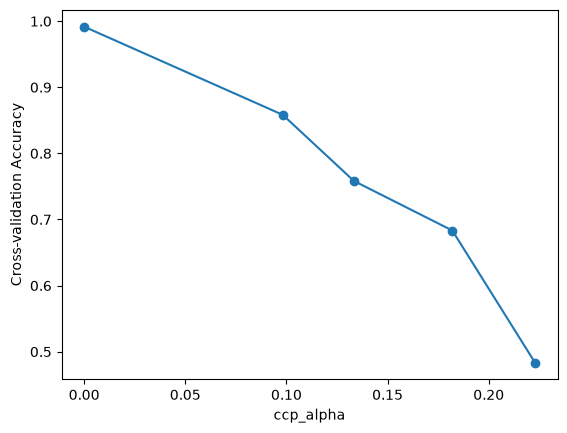

In [7]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

path = clf.cost_complexity_pruning_path(X, y)
alphas = path.ccp_alphas

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

scores = []
for alpha in alphas:
    tree = DecisionTreeClassifier(random_state=0, ccp_alpha=alpha)
    score = cross_val_score(tree, X, y, cv=cv).mean()
    scores.append(score)

plt.plot(alphas, scores, marker='o')
plt.xlabel('ccp_alpha')
plt.ylabel('Cross-validation Accuracy')
plt.show()

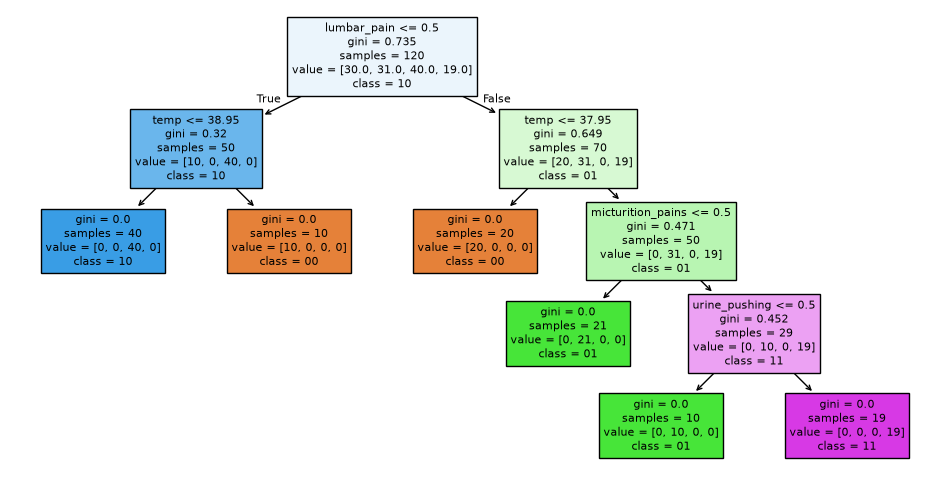

Original leaves: 6
Pruned leaves: 6
IF lumbar_pain <= 0.50 AND temp <= 38.95 THEN (bladder, nephritis) = 10
IF lumbar_pain <= 0.50 AND temp > 38.95 THEN (bladder, nephritis) = 00
IF lumbar_pain > 0.50 AND temp <= 37.95 THEN (bladder, nephritis) = 00
IF lumbar_pain > 0.50 AND temp > 37.95 AND micturition_pains <= 0.50 THEN (bladder, nephritis) = 01
IF lumbar_pain > 0.50 AND temp > 37.95 AND micturition_pains > 0.50 AND urine_pushing <= 0.50 THEN (bladder, nephritis) = 01
IF lumbar_pain > 0.50 AND temp > 37.95 AND micturition_pains > 0.50 AND urine_pushing > 0.50 THEN (bladder, nephritis) = 11


In [8]:
best_score = max(scores)
best_alpha = max(a for a, s in zip(alphas, scores) if s == best_score)

pruned = DecisionTreeClassifier(random_state=0, ccp_alpha=best_alpha)
pruned.fit(X, y)

plt.figure(figsize=(12, 6))
plot_tree(pruned, feature_names=X.columns,
          class_names=pruned.classes_, filled=True)
plt.show()

print("Original leaves:", clf.get_n_leaves())
print("Pruned leaves:", pruned.get_n_leaves())

for rule in tree_to_rules(pruned, list(X.columns)):
    print(rule)

The highest cross-validation accuracy is obtained with a ccp_alpha close to 0. The pruned tree still has 6 leaves, the same as the original tree. Further pruning reduces accuracy, so the original tree is retained.

### 2

In [10]:

import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer

# (a) Load and split the data
df2 = pd.read_csv('../data/communities.data', header=None)

train = df2.iloc[:1495].copy()
test = df2.iloc[1495:].copy()

print("Training set:", train.shape)
print("Test set:", test.shape)

# (b) Remove nonpredictive features and handle missing values
X_train = train.iloc[:, 5:127].replace('?', np.nan).astype(float)
X_test = test.iloc[:, 5:127].replace('?', np.nan).astype(float)

y_train = train.iloc[:, 127].astype(float)
y_test = test.iloc[:, 127].astype(float)

imputer = SimpleImputer(strategy='mean')

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns
)

print("Training missing values:", X_train.isnull().sum().sum())
print("Test missing values:", X_test.isnull().sum().sum())

Training set: (1495, 128)
Test set: (499, 128)
Training missing values: 0
Test missing values: 0


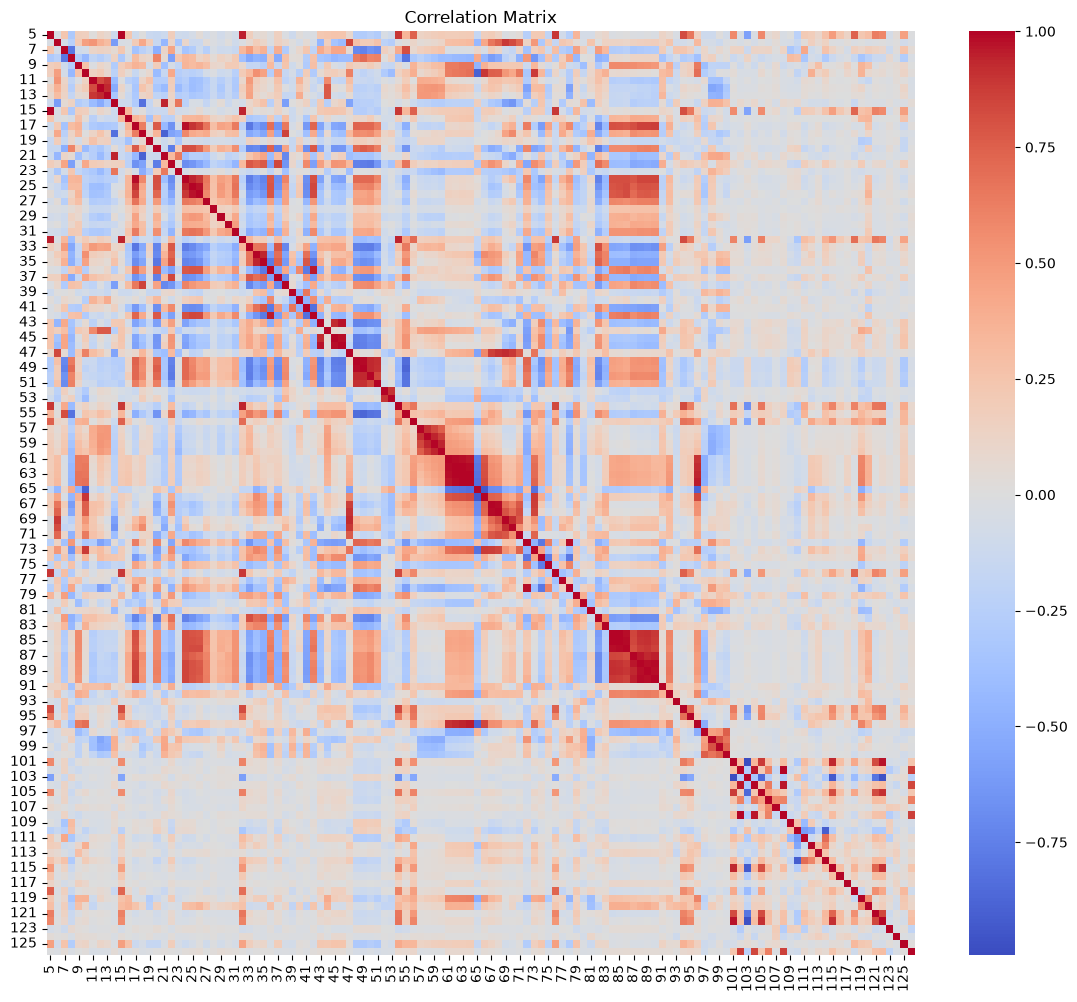

In [11]:
# (c) Correlation Matrix
import seaborn as sns

corr = X_train.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.show()

In [12]:
# (d) Calculate the coefficient of variation
cv = X_train.std() / X_train.mean()

cv = cv.sort_values(ascending=False)
print(cv)


95     4.292923
94     3.470952
54     3.058964
56     2.926635
125    2.552946
         ...   
116    0.144382
109    0.134853
110    0.122813
123    0.115739
103    0.064288
Length: 122, dtype: float64


Selected features: [95, 94, 54, 56, 125, 32, 5, 15, 76, 118, 10]


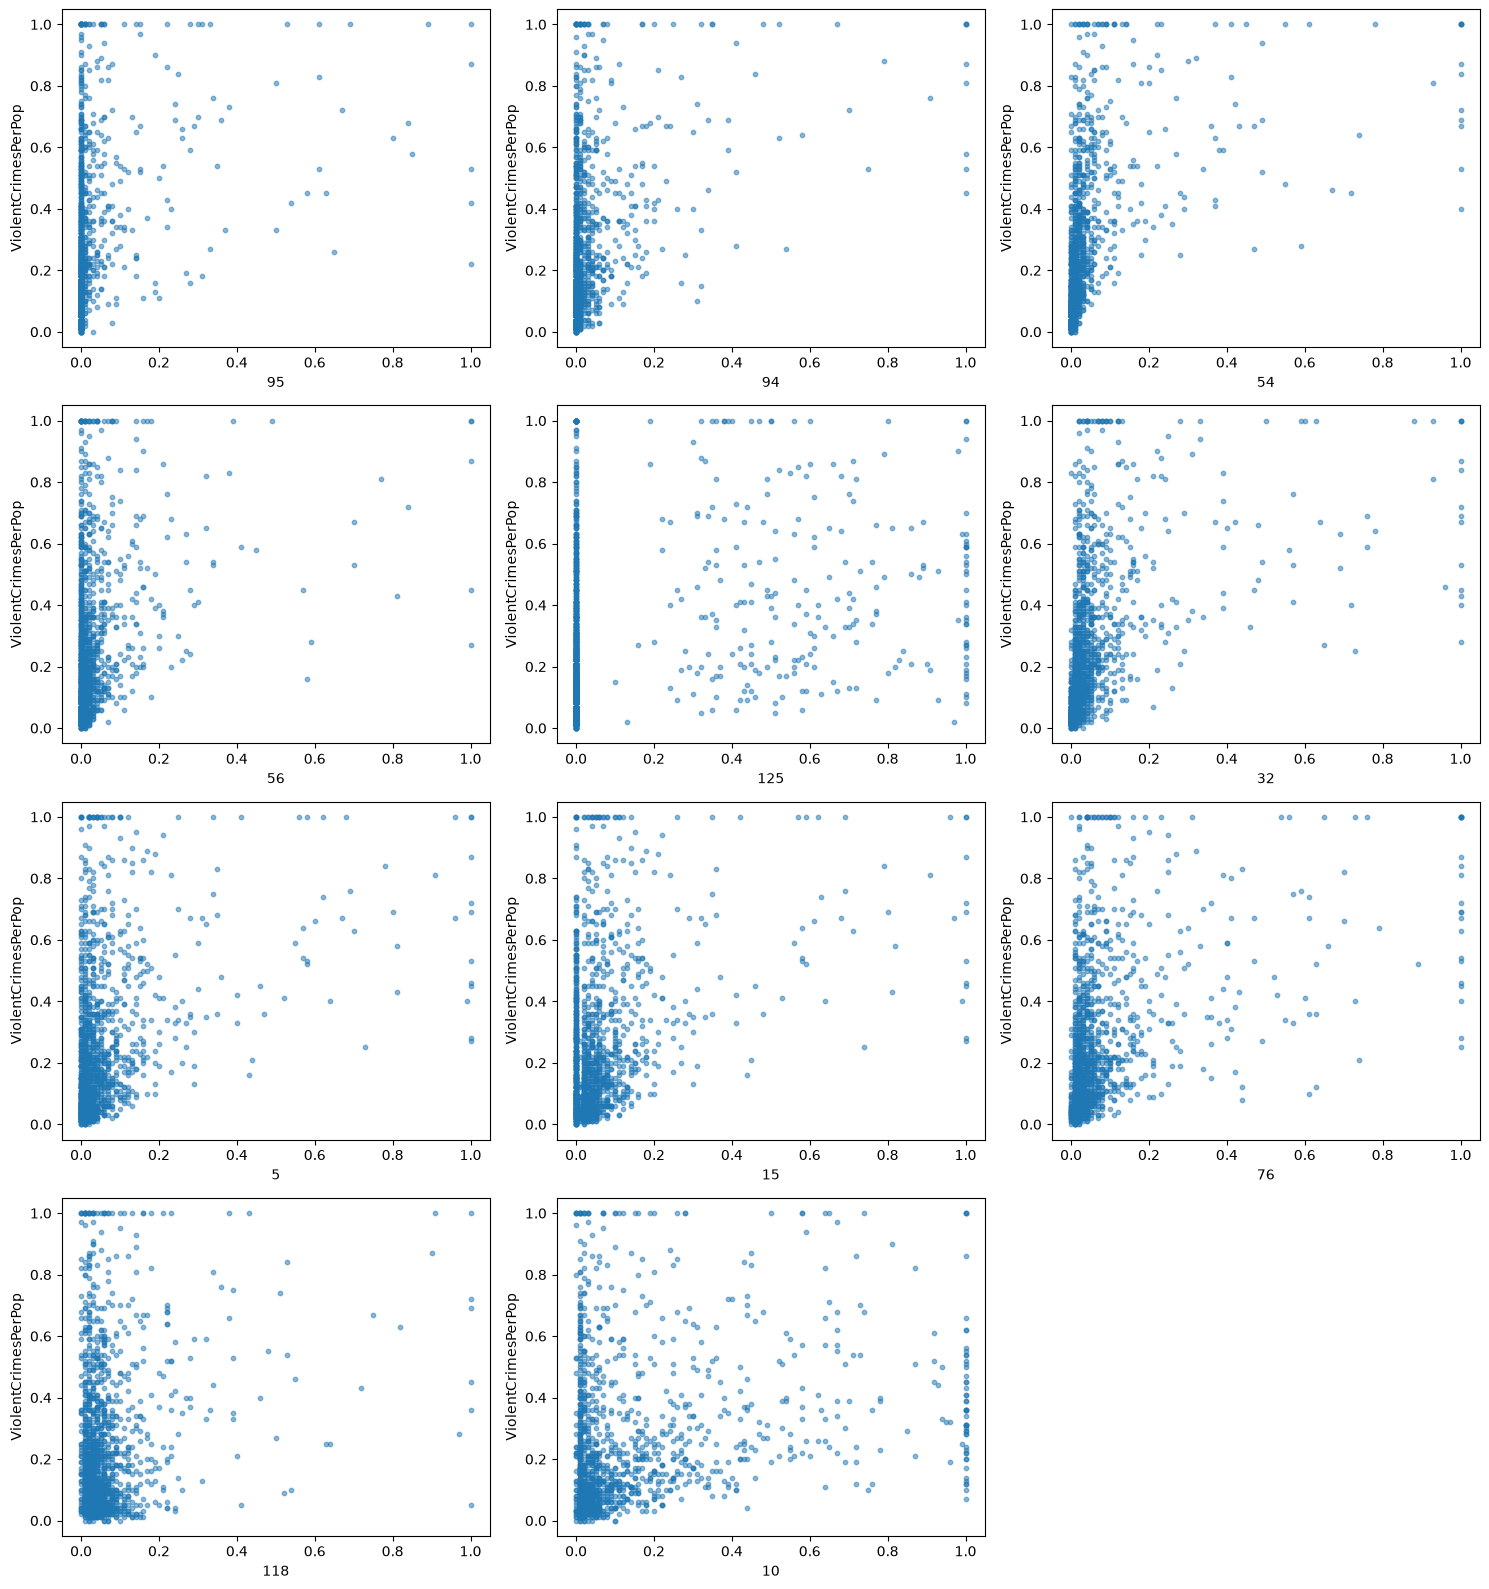

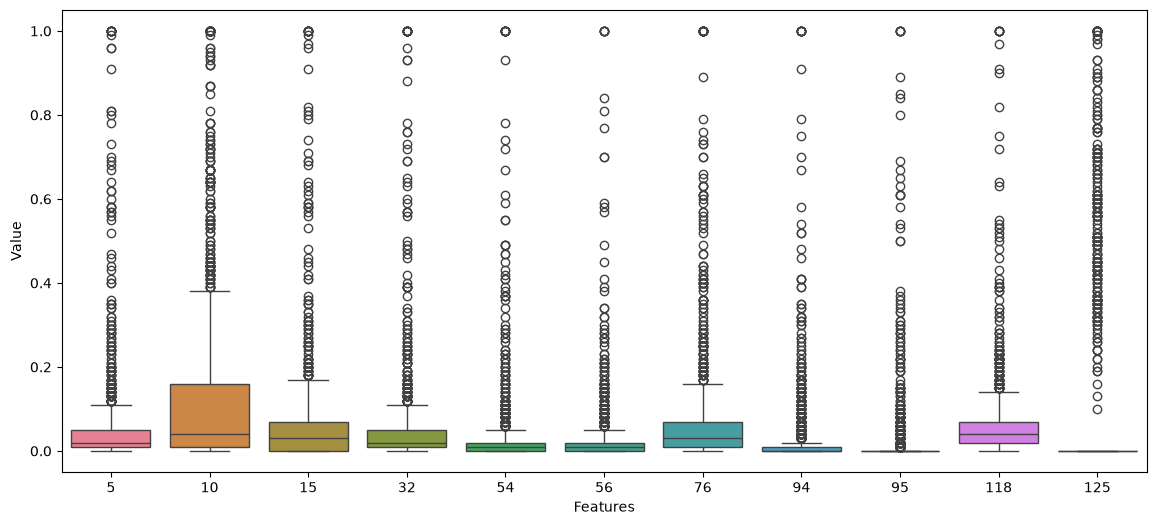

In [13]:
# (e) Select 11 features with the highest CV
top_features = cv.head(11).index
print("Selected features:", list(top_features))

# Scatter plots
fig, axes = plt.subplots(4, 3, figsize=(15, 16))
for i, col in enumerate(top_features):
    axes.flat[i].scatter(X_train[col], y_train, alpha=0.5, s=10)
    axes.flat[i].set_xlabel(str(col))
    axes.flat[i].set_ylabel('ViolentCrimesPerPop')

for ax in axes.flat[len(top_features):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

# Box plots
plt.figure(figsize=(14, 6))
sns.boxplot(data=X_train[top_features])
plt.xlabel('Features')
plt.ylabel('Value')
plt.show()

Most features have values concentrated near zero, and the scatter plots do not show clear linear relationships with the response. Therefore, we cannot determine the statistical significance of these features from the scatter plots alone.

In [14]:
# (f) Least squares regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred = lr.predict(X_test)
mse_lr = mean_squared_error(y_test, y_pred)

print("Test MSE:", mse_lr)

Test MSE: 0.018141971135530104


In [15]:
# (g) Ridge regression with cross-validation
from sklearn.linear_model import RidgeCV

alphas = np.logspace(-4, 4, 100)

ridge = RidgeCV(alphas=alphas, cv=5)
ridge.fit(X_train, y_train)

y_pred_ridge = ridge.predict(X_test)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)

print("Best alpha:", ridge.alpha_)
print("Test MSE:", mse_ridge)


Best alpha: 2.310129700083163
Test MSE: 0.01759961379245253


In [16]:
# (h) LASSO regression
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler

lasso = LassoCV(cv=5, random_state=0, max_iter=100000)
lasso.fit(X_train, y_train)

mse_lasso = mean_squared_error(y_test, lasso.predict(X_test))
selected = X_train.columns[lasso.coef_ != 0]

print("Without standardization:")
print("Best alpha:", lasso.alpha_)
print("Test MSE:", mse_lasso)
print("Selected features:", list(selected))

# LASSO with standardized features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lasso_scaled = LassoCV(cv=5, random_state=0, max_iter=100000)
lasso_scaled.fit(X_train_scaled, y_train)

mse_lasso_scaled = mean_squared_error(
    y_test, lasso_scaled.predict(X_test_scaled)
)
selected_scaled = X_train.columns[lasso_scaled.coef_ != 0]

print("\nWith standardization:")
print("Best alpha:", lasso_scaled.alpha_)
print("Test MSE:", mse_lasso_scaled)
print("Selected features:", list(selected_scaled))


Without standardization:
Best alpha: 0.0001161472362682987
Test MSE: 0.01775820921631968
Selected features: [7, 9, 11, 12, 16, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 33, 34, 38, 39, 41, 43, 44, 45, 49, 50, 51, 53, 54, 55, 56, 60, 64, 66, 68, 69, 72, 73, 74, 75, 76, 77, 79, 80, 81, 82, 83, 84, 87, 90, 91, 92, 93, 94, 95, 96, 97, 99, 104, 105, 107, 109, 111, 113, 115, 116, 117, 118, 119, 120, 123, 124, 125, 126]

With standardization:
Best alpha: 0.0007630833878262516
Test MSE: 0.017805339276862262
Selected features: [7, 9, 11, 12, 16, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 33, 34, 38, 39, 43, 44, 45, 49, 50, 51, 53, 54, 55, 56, 58, 60, 64, 66, 68, 69, 72, 73, 74, 76, 77, 79, 80, 81, 82, 83, 87, 90, 91, 92, 93, 94, 95, 96, 99, 104, 105, 107, 109, 110, 111, 112, 113, 115, 116, 117, 118, 119, 120, 121, 123, 124]


The LASSO model without standardization has a slightly lower test MSE (0.017758) than the standardized model (0.017805). The difference is small, suggesting that standardization has little effect on the prediction performance in this case.

In [22]:
# (i) Principal Components Regression
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV

pcr = make_pipeline(
    StandardScaler(),
    PCA(),
    LinearRegression()
)

params = {'pca__n_components': range(1, X_train.shape[1] + 1)}

grid = GridSearchCV(
    pcr,
    params,
    cv=5,
    scoring='neg_mean_squared_error'
)

grid.fit(X_train, y_train)

mse_pcr = mean_squared_error(y_test, grid.predict(X_test))

print("Best M:", grid.best_params_['pca__n_components'])
print("Test MSE:", mse_pcr)


Best M: 95
Test MSE: 0.018392931230387776


In [21]:
# (j) XGBoost regression
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV

xgb = XGBRegressor(
    objective='reg:squarederror',
    n_estimators=100,
    random_state=0,
    n_jobs=1
)

params = {'reg_alpha': [0, 0.001, 0.01, 0.1, 1, 10]}

grid_xgb = GridSearchCV(
    xgb,
    params,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

grid_xgb.fit(X_train, y_train)

mse_xgb = mean_squared_error(y_test, grid_xgb.predict(X_test))

print("Best alpha:", grid_xgb.best_params_['reg_alpha'])
print("Test MSE:", mse_xgb)


Best alpha: 1
Test MSE: 0.017747461401957192
